In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import mean_squared_error as mse, mean_absolute_error as mae, r2_score

In [3]:
df = pd.read_csv('Data.csv')
df.head()

,Input 1,Input 2,Input 3,Output
0,1.0,30,30,4954.505064
1,1.0,30,35,4218.041602
2,1.0,30,40,3563.425156
3,1.0,30,45,3010.799084
4,1.0,30,50,2553.220128


In [8]:
np.unique(df['Input 1'], return_counts = True)

(array([0.8 , 0.85, 0.9 , 0.95, 1.  ]), array([213, 213, 213, 213, 213]))

In [10]:
np.unique(df['Input 2'], return_counts = True), np.unique(df['Input 3'], return_counts = True)

((array([30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80]),
  array([125, 120, 115, 110, 105, 100,  95,  90,  85,  80,  40])),
 (array([ 30,  35,  40,  45,  50,  55,  60,  65,  70,  75,  80,  85,  90,
          95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145, 150]),
  array([ 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 55, 55, 55, 55, 55, 55,
         55, 50, 50, 50, 50, 50, 50, 50])))

In [31]:
df[(df['Input 1']  == 1) & ( df['Input 2'] == 30)]

,Input 1,Input 2,Input 3,Output
0,1.0,30,30,4954.505064
1,1.0,30,35,4218.041602
2,1.0,30,40,3563.425156
3,1.0,30,45,3010.799084
4,1.0,30,50,2553.220128
5,1.0,30,55,2181.158886
6,1.0,30,60,1879.918280
7,1.0,30,65,1632.523831
8,1.0,30,70,1429.277262
9,1.0,30,75,1260.035634


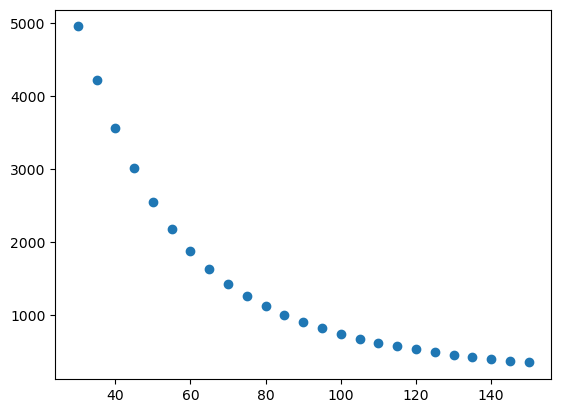

In [32]:
plt.scatter(df[(df['Input 1']  == 1) & ( df['Input 2'] == 30)]['Input 3'], df[(df['Input 1']  == 1) & ( df['Input 2'] == 30)]['Output'])

In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1065 entries, 0 to 1064
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Input 1  1065 non-null   float64
 1   Input 2  1065 non-null   int64  
 2   Input 3  1065 non-null   int64  
 3   Output   1064 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 33.4 KB


In [85]:
df.dropna(inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1064 entries, 0 to 1064
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Input 1  1064 non-null   float64
 1   Input 2  1064 non-null   int64  
 2   Input 3  1064 non-null   int64  
 3   Output   1064 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 41.6 KB


In [86]:
X = df.drop(columns = 'Output')
y = df['Output']

In [104]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2)

In [140]:
model = RandomForestRegressor(
    150,
    criterion = 'absolute_error',
    max_depth = 18
)

In [141]:
cross_val_score(model,X_train,y_train,cv = 5)

array([0.9975063 , 0.99707373, 0.99808176, 0.99711549, 0.9939429 ])

In [142]:
model.fit(X_train,y_train)

,n_estimators,150
,criterion,'absolute_error'
,max_depth,18
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [143]:
print(mse(model.predict(X_train), y_train))
print(r2_score(y_train,model.predict(X_train)))

167.8836418101175
0.9996300525814612


In [144]:
print(mse(model.predict(X_test), y_test))
print(r2_score(y_test,model.predict(X_test)))

781.7787484568265
0.998466097389613


In [179]:
model2 = XGBRegressor(
    objective = 'reg:squarederror',
    n_estimators =50,
    random_state = 42
)

In [180]:
cross_val_score(model2,X_train,y_train,cv = 5)

array([0.9979882 , 0.99850818, 0.99939654, 0.99939849, 0.9987731 ])

In [181]:
model2.fit(X_train,y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [182]:
print(mse(model2.predict(X_train), y_train))
print(r2_score(y_train,model2.predict(X_train)))

17.545419731395725
0.99996133701493


In [183]:
print(mse(model2.predict(X_test), y_test))
print(r2_score(y_test,model2.predict(X_test)))

234.63061270937965
0.999539638919551


In [185]:
import pickle
with open('App/Models/XGBReg-2.pkl', 'wb') as f:
    pickle.dump(model2,f)

In [186]:
df['XGBReg'] = model2.predict(X)

In [187]:
df

,Input 1,Input 2,Input 3,Output,XGBReg
0,1.0,30,30,4954.505064,4954.291504
1,1.0,30,35,4218.041602,4217.946777
2,1.0,30,40,3563.425156,3495.266846
3,1.0,30,45,3010.799084,2906.415771
4,1.0,30,50,2553.220128,2544.588867
...,...,...,...,...,...
1060,0.8,80,95,540.626287,541.133606
1061,0.8,80,100,504.408002,502.527618
1062,0.8,80,105,470.415473,470.454803
1063,0.8,80,110,438.751955,436.366211


In [188]:
df.to_csv('Results.csv')